**24BAD130 Vishal S DL Lab Task-06**

**PART A: DATASET PREPARATION AND TEXT PREPROCESSING**

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from sklearn.metrics import f1_score, confusion_matrix, classification_report

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

In [4]:
df = pd.read_csv("IMDB Dataset.csv")

print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [5]:
print(df.info())
print("\nSentiment Distribution:")
print(df["sentiment"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   review     50000 non-null  object
 1   sentiment  50000 non-null  object
dtypes: object(2)
memory usage: 781.4+ KB
None

Sentiment Distribution:
sentiment
positive    25000
negative    25000
Name: count, dtype: int64


In [6]:
print("Positive Review:")
print(df[df["sentiment"] == "positive"]["review"].iloc[0])

print("\nNegative Review:")
print(df[df["sentiment"] == "negative"]["review"].iloc[0])

Positive Review:
One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show 

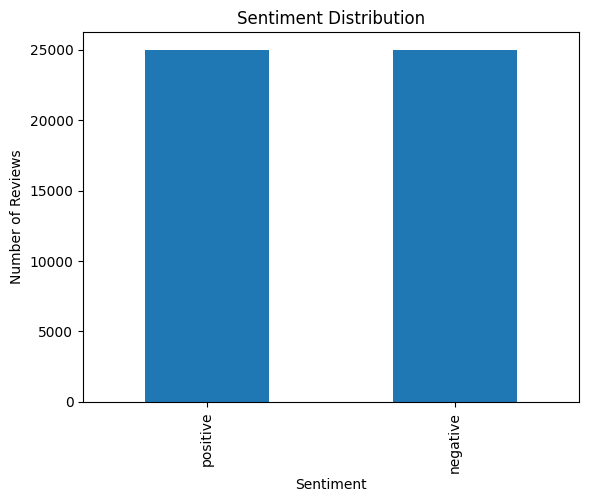

In [7]:
df["sentiment"].value_counts().plot(kind="bar")

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.show()

In [8]:
#Text Preprocessing
def clean_text(text):
    text = text.lower()
    text = re.sub(r"<br\s*/?>", " ", text)
    text = re.sub(r"[^a-zA-Z\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

df["clean_review"] = df["review"].apply(clean_text)

print(df[["review", "clean_review"]].head())

                                              review  \
0  One of the other reviewers has mentioned that ...   
1  A wonderful little production. <br /><br />The...   
2  I thought this was a wonderful way to spend ti...   
3  Basically there's a family where a little boy ...   
4  Petter Mattei's "Love in the Time of Money" is...   

                                        clean_review  
0  one of the other reviewers has mentioned that ...  
1  a wonderful little production the filming tech...  
2  i thought this was a wonderful way to spend ti...  
3  basically there s a family where a little boy ...  
4  petter mattei s love in the time of money is a...  


In [9]:
#Convert Sentiment Labels to Numbers
df["label"] = df["sentiment"].map({
    "negative": 0,
    "positive": 1
})

print(df[["sentiment", "label"]].head())

  sentiment  label
0  positive      1
1  positive      1
2  positive      1
3  negative      0
4  positive      1


In [10]:
#Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    df["clean_review"],
    df["label"],
    test_size=0.20,
    random_state=42,
    stratify=df["label"]
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 40000
Testing samples: 10000


In [11]:
#Tokenization
vocab_size = 10000

tokenizer = Tokenizer(
    num_words=vocab_size,
    oov_token="<OOV>"
)

tokenizer.fit_on_texts(X_train)

X_train_seq = tokenizer.texts_to_sequences(X_train)
X_test_seq = tokenizer.texts_to_sequences(X_test)

print("First tokenized review:")
print(X_train_seq[0])

First tokenized review:
[10, 1031, 11, 121, 1480, 453, 34, 1592, 145, 9, 41, 10, 14, 32, 4, 8622, 1636, 6, 66, 107, 159, 660, 854, 847, 98, 2, 1636, 14, 2801, 357, 3, 18, 57, 1758, 33, 1225, 4, 735, 5, 854, 847, 333, 7775, 6, 76, 178, 9, 2, 1222, 90, 71, 655, 1121, 19, 11, 377, 23, 3, 733, 1604, 2, 302, 14, 9, 1, 2, 1098, 419, 377, 52, 33, 1225, 2754, 1, 264, 629, 1, 1, 299, 5, 1109, 23, 43, 404, 55, 285, 32, 2, 346, 411, 4, 3217, 1868, 3, 1, 12, 91, 8, 59, 2683, 21, 3198, 66, 1, 253, 34, 48, 285, 39, 4, 4357, 8, 14, 568, 660, 3, 363, 19, 10, 414, 22, 537, 1009, 90, 5, 2, 409, 14, 8429, 44, 85, 5, 31, 2, 2127, 82, 45, 21, 120, 323, 1662, 184, 72, 8, 13, 59, 2683, 33, 4296, 9664, 244, 32, 49, 5, 2, 409, 11, 63, 502, 18, 35, 302, 4, 3563]


In [13]:
#Sequence Padding
max_length = 200

X_train_pad = pad_sequences(
    X_train_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

X_test_pad = pad_sequences(
    X_test_seq,
    maxlen=max_length,
    padding="post",
    truncating="post"
)

print("Training data shape:", X_train_pad.shape)
print("Testing data shape:", X_test_pad.shape)

Training data shape: (40000, 200)
Testing data shape: (10000, 200)


**PART B – Embedding Generation**

In [14]:
#Create Validation Dataset
X_train_final, X_val, y_train_final, y_val = train_test_split(
    X_train_pad,
    y_train,
    test_size=0.20,
    random_state=42,
    stratify=y_train
)

print("Training:", X_train_final.shape)
print("Validation:", X_val.shape)
print("Testing:", X_test_pad.shape)

Training: (32000, 200)
Validation: (8000, 200)
Testing: (10000, 200)


In [15]:
#Define Embedding Parameters
embedding_dim = 128

print("Vocabulary Size:", vocab_size)
print("Embedding Dimension:", embedding_dim)

Vocabulary Size: 10000
Embedding Dimension: 128


In [16]:
#Create Embedding Layer
embedding_layer = Embedding(
    input_dim=vocab_size,
    output_dim=embedding_dim,
    input_length=max_length
)

print("Embedding layer created successfully.")

Embedding layer created successfully.


/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


In [17]:
#Check Embedding Representation Shape
sample_embedding = embedding_layer(
    X_train_final[:1]
)

print("Embedding representation shape:")
print(sample_embedding.shape)

Embedding representation shape:
(1, 200, 128)


**PART C – Implementing the LSTM Model**

In [18]:
#Build LSTM Model
model = Sequential()

model.add(
    Embedding(
        input_dim=vocab_size,
        output_dim=embedding_dim,
        input_length=max_length
    )
)

model.add(LSTM(64))

model.add(Dropout(0.5))

model.add(Dense(1, activation="sigmoid"))

In [19]:
#Compile Model
model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [20]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_1 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

**PART D – Model Training and Sentiment Prediction**

In [21]:
#Train the LSTM Model
history = model.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=5,
    batch_size=128
)

Epoch 1/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 94s 368ms/step - accuracy: 0.5723 - loss: 0.6684 - val_accuracy: 0.6115 - val_loss: 0.6481
Epoch 2/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 92s 367ms/step - accuracy: 0.7491 - loss: 0.5537 - val_accuracy: 0.7937 - val_loss: 0.5074
Epoch 3/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 96s 384ms/step - accuracy: 0.6918 - loss: 0.6066 - val_accuracy: 0.7715 - val_loss: 0.5416
Epoch 4/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 95s 378ms/step - accuracy: 0.6641 - loss: 0.6181 - val_accuracy: 0.7319 - val_loss: 0.6122
Epoch 5/5
250/250 ━━━━━━━━━━━━━━━━━━━━ 93s 372ms/step - accuracy: 0.7657 - loss: 0.5373 - val_accuracy: 0.7919 - val_loss: 0.5015


In [22]:
#Display Training Results
print("Final Training Accuracy:",
      history.history["accuracy"][-1])

print("Final Validation Accuracy:",
      history.history["val_accuracy"][-1])

print("Final Training Loss:",
      history.history["loss"][-1])

print("Final Validation Loss:",
      history.history["val_loss"][-1])

Final Training Accuracy: 0.765749990940094
Final Validation Accuracy: 0.7918750047683716
Final Training Loss: 0.5372791886329651
Final Validation Loss: 0.5014983415603638


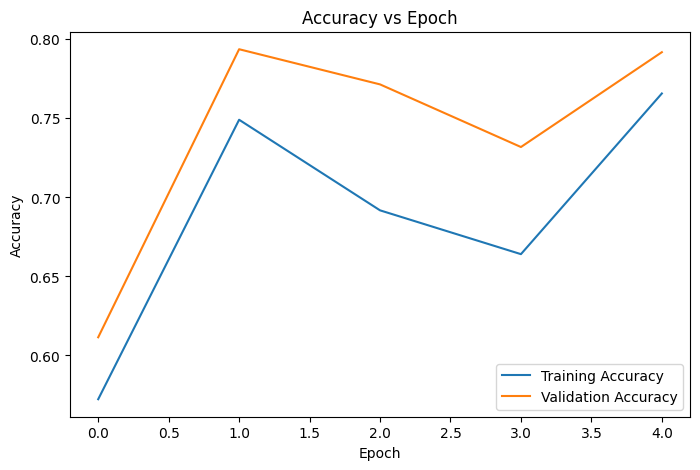

In [23]:
#Accuracy vs Epoch
plt.figure(figsize=(8,5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.title("Accuracy vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

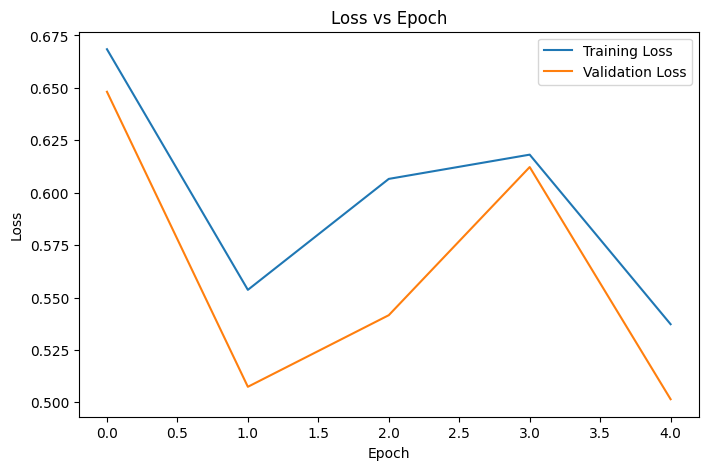

In [24]:
#Loss vs Epoch
plt.figure(figsize=(8,5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.title("Loss vs Epoch")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.show()

In [26]:
#Evaluate Model on Test Dataset
#Test Accuracy
test_loss, test_accuracy = model.evaluate(
    X_test_pad,
    y_test,
    verbose=1
)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 32ms/step - accuracy: 0.7942 - loss: 0.5015
Test Loss: 0.5015390515327454
Test Accuracy: 0.7942000031471252


In [27]:
#Generate Predictions
y_prob = model.predict(X_test_pad)

y_pred = (y_prob >= 0.5).astype(int).flatten()

print("First 10 Predictions:")
print(y_pred[:10])

print("\nActual Values:")
print(np.array(y_test)[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 10s 31ms/step
First 10 Predictions:
[0 1 1 0 0 0 0 0 1 0]

Actual Values:
[0 0 1 0 0 0 0 0 0 0]


In [28]:
#Calculate Evaluation Metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1-Score :", f1)

Accuracy : 0.7942
Precision: 0.7791271347248577
Recall   : 0.8212
F1-Score : 0.7996105160662123


Confusion Matrix:
[[3836 1164]
 [ 894 4106]]


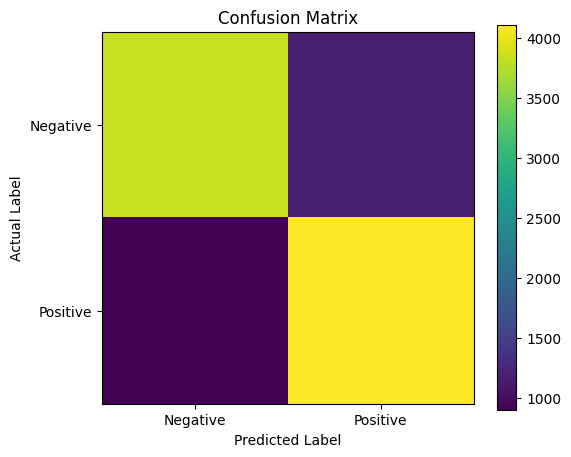

In [29]:
#Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

plt.figure(figsize=(6,5))

plt.imshow(cm)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks([0, 1], ["Negative", "Positive"])
plt.yticks([0, 1], ["Negative", "Positive"])

plt.colorbar()

plt.show()

In [30]:
#Classification Report
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Negative", "Positive"]
    )
)

              precision    recall  f1-score   support

    Negative       0.81      0.77      0.79      5000
    Positive       0.78      0.82      0.80      5000

    accuracy                           0.79     10000
   macro avg       0.80      0.79      0.79     10000
weighted avg       0.80      0.79      0.79     10000



In [31]:
#Predict New Sample Reviews
#Sentiment Prediction Function
def predict_sentiment(review):

    cleaned = clean_text(review)

    sequence = tokenizer.texts_to_sequences([cleaned])

    padded = pad_sequences(
        sequence,
        maxlen=max_length,
        padding="post",
        truncating="post"
    )

    prediction = model.predict(padded, verbose=0)[0][0]

    if prediction >= 0.5:
        return "Positive"
    else:
        return "Negative"

In [32]:
#Test Sample Reviews
review1 = "This movie was amazing and I really enjoyed watching it."

review2 = "The movie was boring and disappointing. I did not enjoy it."

print("Review 1:", predict_sentiment(review1))
print("Review 2:", predict_sentiment(review2))

Review 1: Positive
Review 2: Negative
